# Support Vector Regression（SVR）

SVR 是 SVM(Support Vector Machine) 的迴歸版本。

| 模型 | 任務 |
|---|---|
| SVM / SVC | 分類(Classification) |
| SVR | 迴歸(Regression) |

![](./assets/SVR與線姓回歸的想法差異.png)


## Support Vector 又是什麼？

不是所有資料點都同樣重要。真正會強烈影響模型的，主要是落在邊界附近或超出 ε 範圍的資料。
這些重要資料點就稱為：

$$\boxed{\text{Support Vectors}}$$

所以可以把 SVR 想成：
$$
\boxed{
找出重要的資料點
\rightarrow
建立容許誤差帶
\rightarrow
找到合適的迴歸函數
}
$$

## SVR 跟你前面學的 Polynomial Regression 有什麼差？

| | Polynomial Regression | SVR(RBF) |
|---|---|---|
| 可以處理非線性 | ✓ | ✓ |
| 方法 | 建立 \(x^2,x^3,\dots\) | Kernel |
| 主要控制 | degree | C、epsilon、gamma |
| Scaling | 視情況 | 通常很重要 |
| 對極端值 | 仍可能受影響 | ε 機制可忽略小誤差，但仍非完全抗離群值 |
| 模型解釋 | 相對容易 | 比較困難 |

Polynomial Regression 是：
$$
x
\rightarrow
x,x^2,x^3,x^4
\rightarrow
LinearRegression
$$
SVR(RBF)則不是叫你自己建立：
$$x^2,x^3,x^4$$
而是利用 Kernel 去處理非線性關係。

## SVR 厲害的地方：不只能畫直線

![](./assets/SVR核函數.png)

## SVR參數

![](./assets/SVR參數.png)

## 實作

### 1. 讀取資料集

In [4]:
### Pandas 處理檔案
import pandas as pd

df = pd.read_csv("./data/svr_advertising_100.csv") # 讀取廣告預算與銷售額資料

### 2. 探索資料 (EDA)
先不要急著丟進模型，先確認資料長什麼樣

In [5]:
display(df.head()) ### 查看前 5 筆資料
print("資料形狀：", df.shape) ### 查看資料大小
df.info() ### 查看資料型態與缺失值
display(df.describe()) ### 查看基本統計資料

,advertising_budget,sales
0,5.0,43.36
1,6.0,42.47
2,6.9,49.78
3,7.9,57.86
4,8.8,49.82


資料形狀： (100, 2)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 2 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   advertising_budget  100 non-null    float64
 1   sales               100 non-null    float64
dtypes: float64(2)
memory usage: 1.7 KB


,advertising_budget,sales
count,100.000000,100.00000
mean,52.500000,104.29150
std,27.837643,24.06524
min,5.000000,42.47000
25%,28.750000,92.49750
50%,52.500000,111.54500
75%,76.250000,121.84000
max,100.000000,135.25000


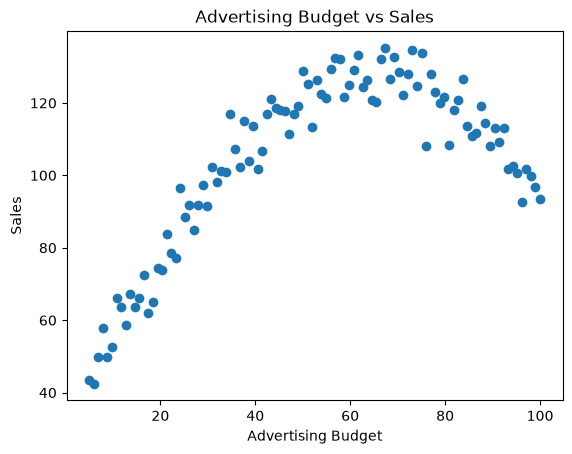

In [6]:
### 也可以先畫散佈圖，觀察 advertising_budget 和 sales 的關係
import matplotlib.pyplot as plt

### 畫出原始資料
plt.scatter(df["advertising_budget"], df["sales"])
plt.xlabel("Advertising Budget")
plt.ylabel("Sales")
plt.title("Advertising Budget vs Sales")
plt.show()

### 3. 資料清理 (Data Cleaning)

將非數值與無限值視為缺失值，移除缺失、負數及完全重複的紀錄。預算與銷售額允許零值，同一預算但銷售額不同的紀錄保留。有效的極端值不自動刪除。

本範例直接刪除缺失資料；若需要補值，請在切分資料後，使用 Pipeline 只從訓練資料學習補值參數，避免資料洩漏。


In [9]:
import numpy as np

### 將欄位轉換成數值，無法轉換的內容設為 NaN
columns = ["advertising_budget", "sales"]
df[columns] = df[columns].apply(pd.to_numeric, errors="coerce")

### 將無限值轉換成 NaN
df = df.replace([np.inf, -np.inf], np.nan)

### 移除缺失值
df = df.dropna(subset=columns).copy()

### 移除負數資料 (廣告預算與銷售額不可為負數)
df = df[(df["advertising_budget"] >= 0) & (df["sales"] >= 0)].copy()

### 移除完全重複資料
df = df.drop_duplicates().reset_index(drop=True)

### 查看清理結果
print("資料筆數：", len(df))

資料筆數： 100


### 4. 選擇 Features 與 Target

In [10]:
### 分割資料：把 Feature 和 Target 拆開
X = df[["advertising_budget"]].copy() # Feature 必須保持二維格式
y = df["sales"].copy() # Target

### 5. 切分 Train / Test

In [11]:
### 切割 Train 80%、Test 20%
from sklearn.model_selection import train_test_split


X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Train 資料筆數：", len(X_train))
print("Test 資料筆數：", len(X_test))

Train 資料筆數： 80
Test 資料筆數： 20


### 6. 建立資料前處理 Pipeline


In [12]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

# SVR 對特徵尺度敏感，標準化參數會在訓練時只從訓練資料學習
preprocessor = Pipeline([
    ("scaler", StandardScaler())
])


### 7. 建立模型


In [13]:
from sklearn.svm import SVR

# 將前處理與 SVR 串接，預測時自動使用相同的標準化
model = Pipeline([
    ("preprocessor", preprocessor),
    ("svr", SVR(
        kernel="rbf", # 使用 RBF Kernel 處理非線性關係
        C=100,        # 超出 epsilon 範圍時的懲罰強度
        epsilon=0.1   # 模型可以容許的誤差範圍
    ))
])

### 8. 訓練模型


In [14]:
model.fit(X_train, y_train)
print("模型訓練完成")

模型訓練完成


### 9. 使用模型預測


In [15]:
# 使用測試資料預測銷售額
y_pred = model.predict(X_test)


### 10. 評估模型表現


In [16]:
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score


### 計算模型評估指標
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = mse ** 0.5
r2 = r2_score(y_test, y_pred)

### 顯示結果
print("MAE：", round(mae, 2))
print("MSE：", round(mse, 2))
print("RMSE：", round(rmse, 2))
print("R²：", round(r2, 4))

MAE： 3.96
MSE： 24.79
RMSE： 4.98
R²： 0.9635


### 11. 視覺化預測結果


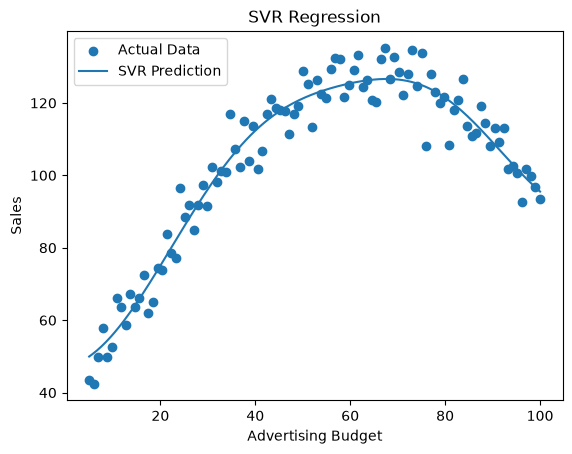

In [17]:
### 視覺化
import numpy as np
import matplotlib.pyplot as plt


### 建立連續的 X，讓 SVR 預測線畫得更平滑
X_plot = pd.DataFrame({
    "advertising_budget": np.linspace(
        df["advertising_budget"].min(),
        df["advertising_budget"].max(),
        300
    )
})


### 使用模型進行預測
y_plot = model.predict(X_plot)


### 畫出原始資料
plt.scatter(
    df["advertising_budget"],
    df["sales"],
    label="Actual Data"
)


### 畫出 SVR 預測曲線
plt.plot(
    X_plot["advertising_budget"],
    y_plot,
    label="SVR Prediction"
)


### 設定圖表
plt.xlabel("Advertising Budget")
plt.ylabel("Sales")
plt.title("SVR Regression")
plt.legend()
plt.show()

## 作業：使用 SVR 預測臺中市房屋租金

本次作業使用政府資料開放平臺提供的「**臺中市不動產實價登錄資訊-租賃案件**」，並使用 **SVR(Support Vector Regression)** 建立模型，並預測**房屋租金**。

資料集：https://data.gov.tw/dataset/102140

也就是建立以下關係：

$$
\boxed{
\text{房屋基本條件}
\longrightarrow
\text{SVR模型}
\longrightarrow
\text{預測房屋租金}
}
$$

學生最後的 Notebook 必須按照以下順序完成：

```text
1. 讀取資料集
        ↓
2. 探索資料 (EDA)
        ↓
3. 資料清理 (Data Cleaning)
        ↓
4. 選擇 Features 與 Target
        ↓
5. 切分 Train / Test
        ↓
6. 建立資料前處理 Pipeline
        ↓
7. 建立模型
        ↓
8. 訓練模型
        ↓
9. 使用模型預測
        ↓
10. 評估模型表現(MAE / RMSE / R²)
        ↓
11. 視覺化預測結果
```



<p style="text-align: center;">Copyright © 2026 Wei-Cheng Chen</p>